In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind

In [2]:
sns.set_palette('Set2')

# Аналитика

## Вводные данные

Представьте, что вы продуктовый аналитик команды платежей. Команда запустила A/B тест новой формы оплаты ЖКХ с упрощённым заполнением реквизитов.


**•	Воронка оплаты ЖКХ:**

1. Открыл форму оплаты → 2. Ввёл реквизиты → 3. Подтвердил платеж → 4. Успешная оплата.



**•	Ключевая метрика:** Конверсия из шага 1 в шаг 4 (успешная оплата).

**•	Гипотеза:** Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.

**•	Длительность теста:** 30 дней (1–30 апреля 2024)

**•	Ваша задача:** Проанализировать результаты A/B теста и дать рекомендацию: запускать новую форму на всех пользователей или нет.

**•	Что нужно сделать:** Провести анализ данных A/B теста и подготовить рекомендацию для продуктовой команды. Данные сплитовались по клиентам, а так же в данных могут встречаться некорректные записи (например, пустые пользователи, аномальные значения) обработайте их соответствующим образом.

**• Области для анализа:**
• Разведочный анализ данных (EDA)
• Работа с выбросами и некорректными записями
• Визуализация результатов
• Статистическая проверка гипотез (с обоснованием выбранного метода)
• Формулировка рекомендации на основе данных

**•	Excel-таблица с данными:** [Данные для кейса по ПА.xlsx](https://edu.tbank.ru/files/cebbefc3-5b29-4f88-b6d4-3336c88d743f)


## Разведочный анализ данных (EDA)

In [3]:
df_users = pd.read_excel(r"C:\Users\Siri\pj\pet_projects\01_ab_testing_product_analytics_tbank\data\dataset_jkh.xlsx", sheet_name='Пользователи')

In [4]:
df_payments = pd.read_excel(r"C:\Users\Siri\pj\pet_projects\01_ab_testing_product_analytics_tbank\data\dataset_jkh.xlsx", sheet_name='Платежи')

In [5]:
df_users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [6]:
df_payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [7]:
df_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


In [8]:
df_users.dtypes

user_id         int64
group          object
age             int64
city           object
device_type    object
dtype: object

In [9]:
df_payments.dtypes

payment_id                  int64
user_id                   float64
group                      object
step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object

In [10]:
df_payments['user_id'] = df_payments['user_id'].astype('Int64')


In [11]:
df_payments.dtypes

payment_id                  int64
user_id                     Int64
group                      object
step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object

In [12]:
df_payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [13]:
print('Количество дубликатов:', df_users.duplicated().sum())
print('Все user_id уникальны:', df_users['user_id'].is_unique)

Количество дубликатов: 0
Все user_id уникальны: True


In [14]:
print('Количество дубликатов', df_payments.duplicated().sum())

Количество дубликатов 0


In [15]:
df_users.isna().sum() #сколько пропусков

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

In [16]:
[df_users['group'].value_counts()]

[group
 A    752
 B    751
 Name: count, dtype: int64]

In [17]:
df_users[df_users['group'].isna()] 

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


In [18]:
df_users['group'] = df_users['group'].fillna('B')

In [19]:
df_users['city'].value_counts()

city
Москва    595
Регион    514
СПб       394
Name: count, dtype: int64

In [20]:
df_users[df_users['city'].isna()]

,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android


In [21]:
df_users['city'] = df_users['city'].fillna(df_users['city'].mode()[0])

In [22]:
df_payments.isna().sum()

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

In [23]:
df_payments[df_payments['user_id'].isna()]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,<NA>,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [24]:
df_payments.shape[0]

2661

In [25]:
df_payments.tail()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2656,7657,2500,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00
2660,99003,<NA>,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [26]:
df_payments = df_payments.drop(index=2660)

In [27]:
df_payments['group'].value_counts()

group
B    1352
A    1308
Name: count, dtype: int64

## Визуализация структуры

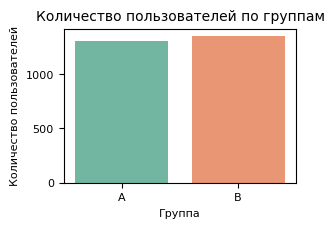

In [28]:
plt.figure(figsize = (3, 2))

sns.countplot(data=df_payments, x='group', hue='group', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Количество пользователей по группам', fontsize=10)
plt.xlabel('Группа', fontsize=8)
plt.ylabel('Количество пользователей', fontsize=8)

plt.show()

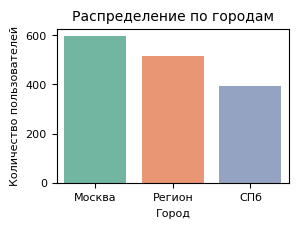

In [29]:
plt.figure(figsize = (3, 2))

sns.countplot(data=df_users, x='city', hue='city', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Распределение по городам', fontsize=10)
plt.xlabel('Город', fontsize=8)
plt.ylabel('Количество пользователей', fontsize=8)

plt.show()

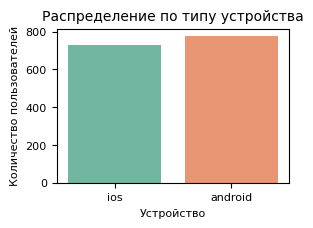

In [30]:
plt.figure(figsize = (3, 2))

sns.countplot(data=df_users, x='device_type', hue='device_type', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Распределение по типу устройства', fontsize=10)
plt.xlabel('Устройство', fontsize=8)
plt.ylabel('Количество пользователей', fontsize=8)

plt.show()

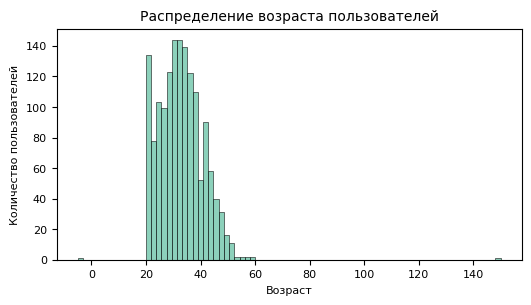

In [31]:
plt.figure(figsize = (6, 3))

sns.histplot(data=df_users, x='age', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Распределение возраста пользователей', fontsize=10)
plt.xlabel('Возраст', fontsize=8)
plt.ylabel('Количество пользователей', fontsize=8)

plt.show()

In [32]:
df_users.loc[df_users['age'] < 0, 'age'] = df_users['age'].mode()[0] 

In [33]:
df_users.loc[df_users['age'] >140, 'age'] = df_users['age'].mode()[0] 

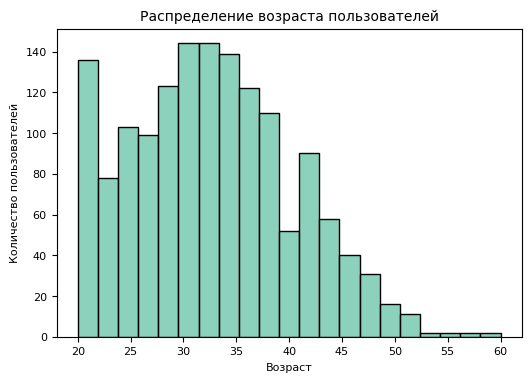

In [34]:
plt.figure(figsize = (6, 4))

sns.histplot(data=df_users, x='age', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Распределение возраста пользователей', fontsize=10)
plt.xlabel('Возраст', fontsize=8)
plt.ylabel('Количество пользователей', fontsize=8)

plt.show()

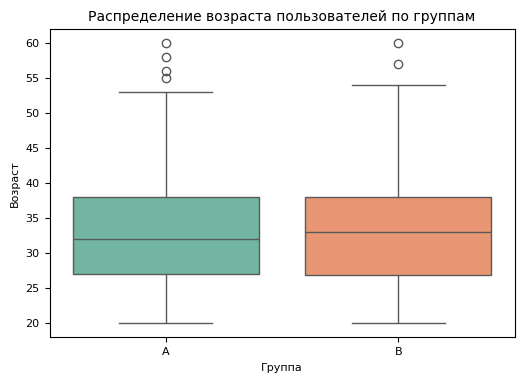

In [35]:
plt.figure(figsize = (6, 4))

sns.boxplot(data=df_users, x='group',y='age', hue='group', legend=False)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title('Распределение возраста пользователей по группам', fontsize=10)
plt.xlabel('Группа', fontsize=8)
plt.ylabel('Возраст', fontsize=8)
plt.show()

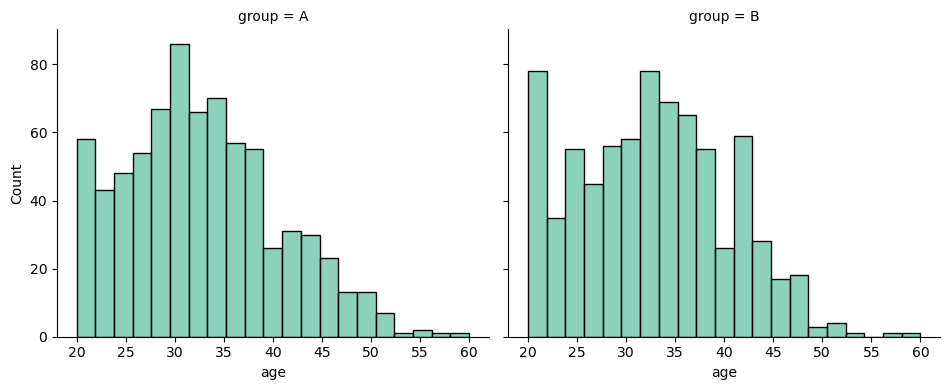

In [36]:
sns.displot(
    data=df_users,
    x='age',
    col='group',
    height=4,
    aspect=1.2
)

plt.show()

In [37]:
from scipy.stats import ttest_ind

group_a = df_users[df_users['group'] == 'A']['age']
group_b = df_users[df_users['group'] == 'B']['age']

stat, p_value = ttest_ind(group_a, group_b, equal_var=False)

print('group_a:', group_a.mean())
print('group_b:', group_b.mean())
print('p-value:', p_value)

group_a: 32.723404255319146
group_b: 32.62765957446808
p-value: 0.8119851544827944


In [38]:
group_a.var(), group_b.var()


(61.20967787630677, 60.585545513782925)

In [39]:
from scipy.stats import levene

stat, p_value = levene(group_a, group_b)

print('p-value:', p_value)

p-value: 0.7494204083508385


По результатам t-теста Уэлча и теста Левена, статистически значимых различий между возрастными характеристиками в группе А и В не обнаржуенно.

In [40]:
df_users.groupby('group')['age'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
group,,,,,,
A,752,32.723404,32.0,7.823661,20,60
B,752,32.627660,33.0,7.783672,20,60


In [41]:
df_users.columns

Index(['user_id', 'group', 'age', 'city', 'device_type'], dtype='object')

In [42]:
pd.crosstab(df_users['group'], df_users['device_type'])

device_type,android,ios
group,,
A,408,344
B,369,383


In [43]:
#Критерий хи-квадрат Пирсона
from scipy.stats import chi2_contingency

device_table = pd.crosstab(
    df_users['group'],
    df_users['device_type']
)

chi2, p_value, dof, expected = chi2_contingency(device_table)

print('Хи-квадрат:',chi2)
print('p-value:', p_value)
print('Степени свободы:', dof)
print('Ожидаемые частоты:\n', expected)

Хи-квадрат: 3.8446747002455393
p-value: 0.04990420130074077
Степени свободы: 1
Ожидаемые частоты:
 [[388.5 363.5]
 [388.5 363.5]]


Статистическое различие между группами в категории виды устройств отсутствует.

In [44]:
pd.crosstab(df_users['group'], df_users['city'])

city,Москва,Регион,СПб
group,,,
A,289,268,195
B,307,246,199


In [45]:
city_table = pd.crosstab(
    df_users['group'],
    df_users['city']
)

chi2, p_value, dof, expected = chi2_contingency(city_table)

print('Хи-квадрат:',chi2)
print('p-value:', p_value)
print('Степени свободы:', dof)
print('Ожидаемые частоты:\n', expected)

Хи-квадрат: 1.5258675393747994
p-value: 0.46629641205934325
Степени свободы: 2
Ожидаемые частоты:
 [[298. 257. 197.]
 [298. 257. 197.]]


Нет основаниий утверждать что распределение пользователей по городам различается между группами А и В.

## Воронка оплат

In [46]:
df_payments.columns

Index(['payment_id', 'user_id', 'group', 'step1_opened', 'step2_entered',
       'step3_confirmed', 'step4_success'],
      dtype='object')

In [47]:
df_payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2660 entries, 0 to 2659
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2660 non-null   int64         
 1   user_id          2660 non-null   Int64         
 2   group            2660 non-null   object        
 3   step1_opened     2660 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: Int64(1), datetime64[ns](4), int64(1), object(1)
memory usage: 148.2+ KB


In [48]:
print('Количество попыток:', df_payments['payment_id'].nunique())
print('Количество пользователей:', df_payments['user_id'].nunique())
print('Повторяющиеся user_id:', df_payments['user_id'].duplicated().sum())
print('Повторяющиеся payment_id:', df_payments['payment_id'].duplicated().sum())

Количество попыток: 2660
Количество пользователей: 1501
Повторяющиеся user_id: 1159
Повторяющиеся payment_id: 0


Сравним количество попыток между группами

In [49]:
attempts_per_user = (
    df_payments
    .groupby(['group','user_id'])
    .size()
    .reset_index(name='attempts')
)

attempts_per_user.groupby(['group'])['attempts'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
group,,,,,,
A,751,1.741678,1.0,0.897319,1,4
B,751,1.800266,2.0,0.906304,1,4


In [50]:
df_payments.groupby('group').agg(
    total_attempts=('payment_id', 'count'),
    successful_attempts=('step4_success', 'count')
)

,total_attempts,successful_attempts
group,,
A,1308,651
B,1352,871


In [51]:
successful_users = (df_payments[df_payments['step4_success'].notna()]
                   .groupby('group')['user_id']
                   .nunique()
    
)

user_conversion = successful_users / 752 *100

print('Успешные пользователи:\n', successful_users)
print('\nКонверсия пользователей:\n', user_conversion)

Успешные пользователи:
 group
A    493
B    604
Name: user_id, dtype: int64

Конверсия пользователей:
 group
A    65.558511
B    80.319149
Name: user_id, dtype: float64


In [60]:
#Абсолютный прирост
absolute_lift = user_conversion['B']-user_conversion['A']

relative_lift = (user_conversion['B']/user_conversion['A']-1)*100

print('Абсолютный прирост', absolute_lift)
print('Относительный прирост', relative_lift)

Абсолютный прирост 14.760638297872333
Относительный прирост 22.515212981744416


## Оценка А/В-теста

**Выберем статистический тест для оценки А/В теста.**
Мы имеем бинарный признак, где 1 - успешная оплата, 0 - нет оплаты. Целевая метрика доля успешных пользователей, которые смогли провести оплату. Данная метрика является пропорцией.

- H0: конверсия А и В равны.
- H1: конверсия А и В различаются. 

---

Выборки А и В независимы друг от дурга, посольку user_id уникальны. Каждый пользователь учитывается один раз, независмо от количества оплат. Также объем выборки является достаточным.

Необходим двустороний тест, поскольку мы можем получить как ухудшение, так и улучшение по целевой метрике.
Также стандартное отклонение нам известно.

---
**Z-тест** позволяет определить, существуют ли различия между долями успеха в двух группах.

- $p_1$ - доля успехов в первой генеральной совокупности;
- $p_2$ - доля успехово во второй генральной совокупности

Двустороний критерий:
- $H_0: p_1 = p_2$
- $H_1: p_1 ≠ p_2$



In [52]:
successful_users

group
A    493
B    604
Name: user_id, dtype: int64

In [54]:
#Z-тест
from statsmodels.stats.proportion import proportions_ztest

successes = [493, 604]
nobs = [752, 752]

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=nobs
)

print("Z-statistic:", z_stat)
print("p-value", p_value)

Z-statistic: -6.442380603310008
p-value 1.1761388286886248e-10


p-value меньше уровня значимости $\alpha = 0,05$. Следовательно отвергаем нулевую гипотезу о равенстве долей успешных оплат в группах А и В.

In [56]:
#Доверительный интервал
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=604,
    nobs1=752,
    count2=493,
    nobs2=752,
    method='wald'
)

print('Нижняя граница:', ci_low)
print('Верхняя граница:', ci_high)

Нижняя граница: 0.10332407620336376
Верхняя граница: 0.19188868975408307


Таким образом, 95%-й доверительный интервал не включает 0, различие сатистически значимо на уровне 5%.

## Результаты и рекомендации

Новая форма автозаполнения ревизитов имеет статистически значимый эффект,  доля успешных оплат выросла на 22,52%. Абсолютный прирост целевой метрики составил 14,76 п.п.

Таким образом, рекомендуется запускать новую конфигурцию формы с автозаполнением реквизитов уже для всех пользователей.

## Дополнительные идеи для анализа



- воронка оплат, как менялась, изменилось ли кол-во попыток?
- увеличилось ли кол-во успешных транзакций?
- время до успешной оплаты, стало ли быстрее оплачивать?
